# 机器学习算法实践 04：线性回归从零实现——基于加州住房数据的房价预测

## 1. 实验目的

本实验使用 California Housing 数据集完成房价预测任务，通过从零实现线性回归算法，理解线性回归模型、均方误差损失函数以及梯度下降算法的基本原理，并使用 scikit-learn 的 LinearRegression 进行对比实验。

本实验主要完成以下内容：

1. 理解回归问题与分类问题的区别；
2. 理解线性回归模型的基本原理；
3. 理解均方误差（MSE）损失函数；
4. 理解梯度下降优化算法；
5. 从零实现多元线性回归模型；
6. 使用 MSE、RMSE 和 R² 评价回归模型；
7. 与 sklearn LinearRegression 进行对比分析。

## 2. 线性回归算法原理

### 2.1 回归问题

机器学习任务通常可以分为分类问题和回归问题。

分类问题的预测结果是离散的类别，例如垃圾短信识别中的 `ham` 和 `spam`；回归问题的预测结果则是连续数值，例如根据住房特征预测房价。

本实验使用线性回归解决房价预测问题，即根据多个住房特征预测房屋价值。

---

### 2.2 线性回归模型

最简单的一元线性回归模型可以表示为：

$$
\hat{y} = wx + b
$$

其中：

- $x$：输入特征；
- $\hat{y}$：模型预测值；
- $w$：权重（weight）；
- $b$：偏置（bias）。

线性回归模型训练的过程，本质上就是根据训练数据寻找合适的参数 $w$ 和 $b$，使模型预测值尽可能接近真实值。

当输入包含多个特征时，可以使用多元线性回归：

$$
\hat{y} = w_1x_1 + w_2x_2 + \cdots + w_nx_n + b
$$

也可以写成矩阵形式：

$$
\hat{y} = Xw + b
$$

其中 $x_1,x_2,\ldots,x_n$ 表示不同的输入特征，$w_1,w_2,\ldots,w_n$ 表示每个特征对应的权重。

---

### 2.3 均方误差损失函数

为了衡量模型预测值与真实值之间的差距，本实验采用均方误差（Mean Squared Error，MSE）作为损失函数：

$$
MSE = \frac{1}{m}\sum_{i=1}^{m}(\hat{y}_i-y_i)^2
$$

其中：

- $m$：样本数量；
- $y_i$：第 $i$ 个样本的真实值；
- $\hat{y}_i$：第 $i$ 个样本的预测值。

MSE 越小，说明模型预测值整体上越接近真实值。因此，线性回归模型训练的目标就是寻找合适的参数，使 MSE 尽可能小。

---

### 2.4 梯度下降

梯度下降（Gradient Descent）是一种常用的参数优化方法。

在线性回归中，通过计算损失函数关于权重 $w$ 和偏置 $b$ 的梯度，可以确定参数调整的方向，然后不断更新模型参数，使损失函数逐渐减小。

参数更新过程可以表示为：

$$
w \leftarrow w-\eta\frac{\partial Loss}{\partial w}
$$

$$
b \leftarrow b-\eta\frac{\partial Loss}{\partial b}
$$

其中 $\eta$ 表示学习率（Learning Rate），用于控制每次参数更新的步长。

学习率过小会导致模型训练速度较慢；学习率过大则可能导致模型无法稳定收敛。

因此，线性回归的基本训练过程可以概括为：

1. 初始化权重 $w$ 和偏置 $b$；
2. 根据 $\hat{y}=Xw+b$ 计算预测值；
3. 计算预测值与真实值之间的 MSE；
4. 计算损失函数关于参数的梯度；
5. 根据梯度更新 $w$ 和 $b$；
6. 重复上述过程，直到损失函数逐渐稳定。

## 3. California Housing 数据集

本实验使用 scikit-learn 提供的 California Housing 数据集进行房价预测。

该数据集包含加利福尼亚不同地区的住房统计信息，每个样本包含收入中位数、房龄、平均房间数、人口、地理位置等特征，预测目标为该地区的房屋价值中位数。

本实验首先对数据进行基本分析，然后划分训练集和测试集，为后续从零实现线性回归模型做准备。

### 3.1 导入库并加载数据

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
# 加载 California Housing 数据集
housing = fetch_california_housing()

# 转换为 DataFrame，方便观察
df = pd.DataFrame(housing.data, columns=housing.feature_names)

# 加入预测目标
df["MedHouseVal"] = housing.target

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


### 3.2 数据基本信息

首先查看数据集的样本数量、特征数量以及各个特征的基本统计信息，并检查数据中是否存在缺失值。

In [4]:
print("数据集形状：", df.shape)
print("\n特征名称：")
print(housing.feature_names)

print("\n数据基本信息：")
df.info()

数据集形状： (20640, 9)

特征名称：
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

数据基本信息：
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [5]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [6]:
print("各列缺失值数量：")
print(df.isnull().sum())

各列缺失值数量：
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


### 3.3 特征与预测目标

将数据划分为输入特征 $X$ 和预测目标 $y$。

其中 $X$ 包含 8 个住房相关特征，$y$ 为房屋价值中位数 `MedHouseVal`。

In [9]:
# 输入特征
X = housing.data

# 预测目标
y = housing.target

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (20640, 8)
y shape: (20640,)


### 3.4 划分训练集和测试集

按照 8:2 的比例将数据划分为训练集和测试集。

训练集用于模型参数学习，测试集不参与模型训练，用于评价模型对未见数据的预测能力。设置 `random_state=42` 保证每次运行得到相同的数据划分结果。

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16512, 8)
X_test: (4128, 8)
y_train: (16512,)
y_test: (4128,)


### 3.5 数据集分析

California Housing 数据集共有 **20640 个样本**，原始数据包含 **8 个输入特征**。在加入预测目标 `MedHouseVal` 后，DataFrame 的形状为 `(20640, 9)`。

8 个输入特征分别为：

- `MedInc`：收入中位数；
- `HouseAge`：房龄中位数；
- `AveRooms`：平均房间数；
- `AveBedrms`：平均卧室数；
- `Population`：人口数量；
- `AveOccup`：平均居住人数；
- `Latitude`：纬度；
- `Longitude`：经度。

预测目标为 `MedHouseVal`，表示房屋价值中位数。

缺失值检查结果表明，所有特征以及预测目标的缺失值数量均为 **0**，因此本实验不需要进行缺失值填充或删除处理。

按照 8:2 的比例划分数据集后：

- 训练集包含 **16512 个样本**；
- 测试集包含 **4128 个样本**；
- 每个样本包含 **8 个输入特征**。

训练集用于学习线性回归模型的参数，测试集用于评价模型在未参与训练的数据上的预测能力。

## 4. 特征标准化

California Housing 数据集中的不同特征具有不同的数值尺度。例如，收入中位数、人口数量以及经纬度等特征的取值范围存在较大差异。

为了使梯度下降过程更加稳定，并加快模型参数的优化，本实验对输入特征进行标准化处理。

标准化公式为：

$$
x' = \frac{x-\mu}{\sigma}
$$

其中 $\mu$ 为该特征的均值，$\sigma$ 为该特征的标准差。

标准化后，各个特征具有相近的数据尺度，有利于后续使用梯度下降训练线性回归模型。

In [11]:
# 创建标准化器
scaler = StandardScaler()

# 使用训练集计算均值和标准差，并对训练集进行标准化
X_train_scaled = scaler.fit_transform(X_train)

# 使用训练集得到的均值和标准差对测试集进行标准化
X_test_scaled = scaler.transform(X_test)

print("标准化前训练集前 3 个样本：")
print(X_train[:3])

print("\n标准化后训练集前 3 个样本：")
print(X_train_scaled[:3])

标准化前训练集前 3 个样本：
[[ 3.25960000e+00  3.30000000e+01  5.01765650e+00  1.00642055e+00
   2.30000000e+03  3.69181380e+00  3.27100000e+01 -1.17030000e+02]
 [ 3.81250000e+00  4.90000000e+01  4.47354497e+00  1.04100529e+00
   1.31400000e+03  1.73809524e+00  3.37700000e+01 -1.18160000e+02]
 [ 4.15630000e+00  4.00000000e+00  5.64583333e+00  9.85119048e-01
   9.15000000e+02  2.72321429e+00  3.46600000e+01 -1.20480000e+02]]

标准化后训练集前 3 个样本：
[[-0.326196    0.34849025 -0.17491646 -0.20836543  0.76827628  0.05137609
  -1.3728112   1.27258656]
 [-0.03584338  1.61811813 -0.40283542 -0.12853018 -0.09890135 -0.11736222
  -0.87669601  0.70916212]
 [ 0.14470145 -1.95271028  0.08821601 -0.25753771 -0.44981806 -0.03227969
  -0.46014647 -0.44760309]]


## 5. 从零实现线性回归

本实验不直接调用 sklearn 的线性回归模型，而是使用 NumPy 从零实现多元线性回归。

模型采用梯度下降算法进行训练。训练过程中首先根据当前参数计算预测值，然后计算参数梯度，并根据学习率不断更新权重和偏置，使模型的均方误差逐渐减小。

In [12]:
# 获取训练集样本数量和特征数量
n_samples, n_features = X_train_scaled.shape

# 初始化权重和偏置
w = np.zeros(n_features)
b = 0.0

print("样本数量：", n_samples)
print("特征数量：", n_features)
print("初始权重 w：", w)
print("初始偏置 b：", b)

样本数量： 16512
特征数量： 8
初始权重 w： [0. 0. 0. 0. 0. 0. 0. 0.]
初始偏置 b： 0.0


In [13]:
y_pred = X_train_scaled @ w + b

print("预测结果形状：", y_pred.shape)
print("前 5 个预测值：", y_pred[:5])
print("前 5 个真实值：", y_train[:5])

预测结果形状： (16512,)
前 5 个预测值： [0. 0. 0. 0. 0.]
前 5 个真实值： [1.03  3.821 1.726 0.934 0.965]


In [14]:
y_pred = X_train_scaled @ w + b

print("预测结果形状：", y_pred.shape)
print("前 5 个预测值：", y_pred[:5])
print("前 5 个真实值：", y_train[:5])

预测结果形状： (16512,)
前 5 个预测值： [0. 0. 0. 0. 0.]
前 5 个真实值： [1.03  3.821 1.726 0.934 0.965]


In [15]:
mse = np.mean((y_pred - y_train) ** 2)

print("初始 MSE：", mse)

初始 MSE： 5.629742323103131


In [16]:
# 计算预测误差
error = y_pred - y_train

# 计算权重和偏置的梯度
dw = (2 / n_samples) * (X_train_scaled.T @ error)
db = (2 / n_samples) * np.sum(error)

print("dw：", dw)
print("db：", db)

dw： [-1.59703913 -0.23980869 -0.36647763  0.11874312  0.06019684  0.05094169
  0.3306322   0.10717635]
db： -4.143893874757752


In [17]:
learning_rate = 0.01

w = w - learning_rate * dw
b = b - learning_rate * db

print("更新后的 w：", w)
print("更新后的 b：", b)

更新后的 w： [ 0.01597039  0.00239809  0.00366478 -0.00118743 -0.00060197 -0.00050942
 -0.00330632 -0.00107176]
更新后的 b： 0.04143893874757752


In [18]:
y_pred_new = X_train_scaled @ w + b

mse_new = np.mean((y_pred_new - y_train) ** 2)

print("参数更新前 MSE：", mse)
print("参数更新后 MSE：", mse_new)

参数更新前 MSE： 5.629742323103131
参数更新后 MSE： 5.4312188366008


### 5.7 完整实现梯度下降线性回归

前面的实验完成了一次梯度下降参数更新，MSE 从 **5.6297** 下降至 **5.4312**，说明梯度计算和参数更新方向正确。

接下来将预测、梯度计算和参数更新过程封装为一个线性回归类，并通过多轮迭代不断优化模型参数。同时记录每轮训练的 MSE，用于观察模型的收敛过程。

In [19]:
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, epochs=1000):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.w = None
        self.b = None
        self.loss_history = []

    def fit(self, X, y):
        # 样本数量和特征数量
        n_samples, n_features = X.shape

        # 初始化参数
        self.w = np.zeros(n_features)
        self.b = 0.0

        # 梯度下降
        for epoch in range(self.epochs):

            # 1. 计算预测值
            y_pred = X @ self.w + self.b

            # 2. 计算误差
            error = y_pred - y

            # 3. 计算 MSE
            loss = np.mean(error ** 2)
            self.loss_history.append(loss)

            # 4. 计算梯度
            dw = (2 / n_samples) * (X.T @ error)
            db = (2 / n_samples) * np.sum(error)

            # 5. 更新参数
            self.w -= self.learning_rate * dw
            self.b -= self.learning_rate * db

        return self

    def predict(self, X):
        return X @ self.w + self.b

In [20]:
# 创建手写线性回归模型
manual_model = LinearRegressionGD(
    learning_rate=0.01,
    epochs=1000
)

# 使用标准化后的训练集训练模型
manual_model.fit(X_train_scaled, y_train)

print("训练完成")
print("最终权重 w：", manual_model.w)
print("最终偏置 b：", manual_model.b)

print("\n初始 MSE：", manual_model.loss_history[0])
print("最终 MSE：", manual_model.loss_history[-1])

训练完成
最终权重 w： [ 0.8580605   0.1501549  -0.25253771  0.28100715  0.00710958 -0.04344213
 -0.68321834 -0.65415242]
最终偏置 b： 2.0719469338916703

初始 MSE： 5.629742323103131
最终 MSE： 0.5246173749384619


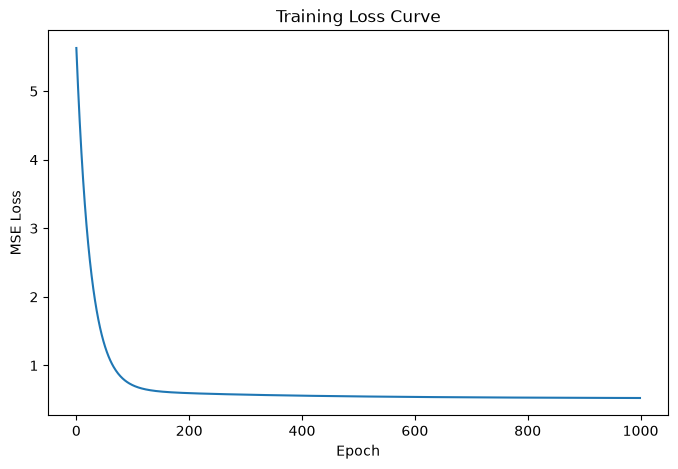

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(manual_model.loss_history)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Loss Curve")

plt.show()

### 5.10 训练过程分析

手写线性回归模型经过 1000 轮梯度下降训练后，训练集 MSE 从初始的 **5.6297** 下降至 **0.5246**。

从 Loss 曲线可以看出，训练初期损失下降速度较快，说明梯度下降能够快速调整模型参数；随着训练进行，损失下降速度逐渐减慢，并最终趋于稳定。

实验结果表明，本实验实现的梯度下降算法能够有效优化线性回归模型参数，同时学习率 `0.01` 在当前实验设置下能够使训练过程保持稳定并逐渐收敛。

## 6. 手写线性回归实验结果

完成模型训练后，使用测试集评价手写线性回归模型的预测性能。

测试集没有参与模型参数的学习，因此测试集上的评价结果能够更好地反映模型对未见数据的预测能力。

In [22]:
# 使用手写模型预测测试集
y_pred_manual = manual_model.predict(X_test_scaled)

print("前 10 个真实值：")
print(y_test[:10])

print("\n前 10 个预测值：")
print(y_pred_manual[:10])

前 10 个真实值：
[0.477   0.458   5.00001 2.186   2.78    1.587   1.982   1.575   3.4
 4.466  ]

前 10 个预测值：
[0.79795208 1.70856504 2.63039776 2.79875658 2.46876694 2.05398258
 2.66444346 2.17279691 2.57357574 3.99158605]


In [23]:
# 计算测试集评价指标
manual_mse = mean_squared_error(y_test, y_pred_manual)
manual_rmse = np.sqrt(manual_mse)
manual_r2 = r2_score(y_test, y_pred_manual)

print("手写线性回归测试结果")
print(f"MSE  = {manual_mse:.4f}")
print(f"RMSE = {manual_rmse:.4f}")
print(f"R²   = {manual_r2:.4f}")

手写线性回归测试结果
MSE  = 0.5546
RMSE = 0.7447
R²   = 0.5768


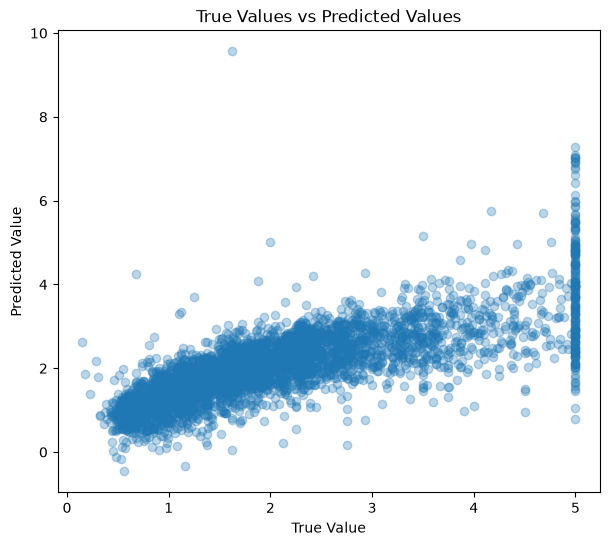

In [24]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred_manual, alpha=0.3)

plt.xlabel("True Value")
plt.ylabel("Predicted Value")
plt.title("True Values vs Predicted Values")

plt.show()

In [25]:
manual_mse = mean_squared_error(y_test, y_pred_manual)
manual_rmse = np.sqrt(manual_mse)
manual_r2 = r2_score(y_test, y_pred_manual)

print("手写线性回归测试结果")
print(f"MSE  = {manual_mse:.4f}")
print(f"RMSE = {manual_rmse:.4f}")
print(f"R²   = {manual_r2:.4f}")

手写线性回归测试结果
MSE  = 0.5546
RMSE = 0.7447
R²   = 0.5768


### 6.4 手写模型结果分析

手写线性回归模型在测试集上的评价结果如下：

- MSE：**0.5546**
- RMSE：**0.7447**
- R²：**0.5768**

测试集 MSE 与训练结束时的训练集 MSE（0.5246）较为接近，说明模型在训练集和测试集上的误差没有出现明显差异。

R² 为 0.5768，说明当前线性回归模型能够解释测试数据中一部分目标变量的变化，但仍存在一定预测误差。由于线性回归只能描述输入特征与预测目标之间的线性关系，因此对于数据中可能存在的非线性关系，其表达能力存在一定限制。

## 7. sklearn LinearRegression 对比实验

为了验证手写线性回归算法的正确性，本实验进一步使用 scikit-learn 提供的 `LinearRegression` 模型，在相同的数据划分下进行训练和测试。

通过比较手写模型与 sklearn 模型的 MSE、RMSE 和 R²，分析从零实现的梯度下降线性回归与成熟机器学习库实现之间的差异。

In [26]:
from sklearn.linear_model import LinearRegression

# 创建 sklearn 线性回归模型
sklearn_model = LinearRegression()

# 使用相同的标准化训练集进行训练
sklearn_model.fit(X_train_scaled, y_train)

# 测试集预测
y_pred_sklearn = sklearn_model.predict(X_test_scaled)

In [27]:
sklearn_mse = mean_squared_error(y_test, y_pred_sklearn)
sklearn_rmse = np.sqrt(sklearn_mse)
sklearn_r2 = r2_score(y_test, y_pred_sklearn)

print("sklearn LinearRegression 测试结果")
print(f"MSE  = {sklearn_mse:.4f}")
print(f"RMSE = {sklearn_rmse:.4f}")
print(f"R²   = {sklearn_r2:.4f}")

sklearn LinearRegression 测试结果
MSE  = 0.5559
RMSE = 0.7456
R²   = 0.5758


In [28]:
results = pd.DataFrame({
    "Model": ["Manual Linear Regression", "sklearn LinearRegression"],
    "MSE": [manual_mse, sklearn_mse],
    "RMSE": [manual_rmse, sklearn_rmse],
    "R²": [manual_r2, sklearn_r2]
})

results

,Model,MSE,RMSE,R²
0,Manual Linear Regression,0.554580,0.744701,0.576789
1,sklearn LinearRegression,0.555892,0.745581,0.575788


In [29]:
prediction_diff = np.mean(
    np.abs(y_pred_manual - y_pred_sklearn)
)

print("两个模型预测值的平均绝对差异：", prediction_diff)

两个模型预测值的平均绝对差异： 0.06098673525483898


### 7.5 对比实验分析

sklearn `LinearRegression` 在测试集上的结果为：

- MSE：**0.5559**
- RMSE：**0.7456**
- R²：**0.5758**

手写梯度下降线性回归的测试结果为：

- MSE：**0.5546**
- RMSE：**0.7447**
- R²：**0.5768**

两种方法得到的评价指标非常接近，说明本实验从零实现的线性回归模型能够正确完成参数学习和预测任务。

手写模型采用梯度下降方法，通过多轮迭代逐渐优化权重和偏置；sklearn 的 `LinearRegression` 则通过数值线性代数方法求解最小二乘问题。因此，两种方法的参数求解过程不同，最终预测结果可能存在一定差异。

在当前测试集上，手写模型的 MSE 和 RMSE 略低、R² 略高，但差异很小，因此不能据此认为手写模型整体优于 sklearn 模型。该对比实验的主要目的在于验证手写线性回归和梯度下降实现的正确性。

此外，两个模型在测试集上的预测值平均绝对差异约为 **0.0610**，进一步说明手写梯度下降线性回归与 sklearn `LinearRegression` 得到了较为接近的预测结果。

需要注意的是，两种方法的参数求解方式不同。手写模型通过有限轮次的梯度下降迭代优化参数，而 sklearn `LinearRegression` 通过数值线性代数方法求解最小二乘问题，因此两者的预测结果并不完全相同。

## 8. 实验结果分析

本实验基于 California Housing 数据集完成房价预测任务，并使用 NumPy 从零实现基于梯度下降的多元线性回归模型。

### 8.1 梯度下降训练效果

模型参数初始化为 0 后，初始训练集 MSE 为 **5.6297**。经过 1000 轮梯度下降训练后，MSE 下降至 **0.5246**。

从训练 Loss 曲线可以观察到，训练初期损失快速下降，随后下降速度逐渐减慢并趋于稳定，说明梯度下降能够有效优化模型参数，并且模型最终基本收敛。

### 8.2 测试集预测效果

手写线性回归模型在测试集上取得：

- MSE：**0.5546**
- RMSE：**0.7447**
- R²：**0.5768**

训练集最终 MSE 与测试集 MSE 较为接近，没有出现明显的训练误差很低而测试误差大幅增加的现象。

R² 为 0.5768，说明线性回归能够解释目标变量的部分变化，但仍存在一定预测误差。线性回归只能建立输入特征与目标变量之间的线性关系，而实际房价受到多种复杂因素影响，因此简单线性模型的表达能力存在一定限制。

### 8.3 与 sklearn 模型对比

sklearn `LinearRegression` 的测试集 MSE、RMSE 和 R² 分别为 **0.5559、0.7456 和 0.5758**，与手写模型的结果非常接近。

实验结果表明，从零实现的线性回归模型能够正确完成前向预测、MSE 计算、梯度计算以及参数更新，并通过梯度下降学习到有效的模型参数。

## 9. 实验总结

本实验使用 California Housing 数据集完成了基于多元线性回归的房价预测任务，并从零实现了基于梯度下降的线性回归模型。

通过本次实验主要掌握了以下内容：

1. 理解分类问题与回归问题的区别；
2. 理解一元线性回归和多元线性回归的基本模型；
3. 理解 MSE 损失函数的作用；
4. 理解梯度以及梯度下降的基本思想；
5. 理解学习率对模型参数更新的作用；
6. 掌握特征标准化及避免数据泄漏的基本方法；
7. 使用 NumPy 从零实现线性回归模型；
8. 使用 MSE、RMSE 和 R² 评价回归模型；
9. 将手写模型与 sklearn `LinearRegression` 进行对比验证。

实验中，手写模型的训练集 MSE 从 **5.6297** 下降至 **0.5246**，测试集取得 **0.5546 的 MSE、0.7447 的 RMSE 和 0.5768 的 R²**。sklearn `LinearRegression` 的测试结果分别为 **0.5559、0.7456 和 0.5758**，两种实现结果非常接近，从而验证了手写线性回归和梯度下降实现的正确性。